# HUSTmotor — Source-Domain Feature Validation

**Université de technologie de Compiègne (UTC)** · Multimodal motor fault diagnosis workshop  
**Acoustic modality | Phase 4A | Feature selection without target-domain feedback**

This notebook tests whether the 11 engineered acoustic features transfer across **source** motor speeds, to guide a later CNN + statistical-feature fusion experiment.

> **Important:** This is **not** a target-domain accuracy benchmark. This notebook intentionally never fits, plots, scores, or selects models using the actual unseen target domain. We already explored target-domain behavior in the previous Random Forest notebook; this is a *source-only follow-up*, not a fresh independent test of those target recordings.

**Previously completed (exploratory) acoustic experiments:** z-score CNN (48.45% overall mean target accuracy), RMS CNN (38.19%), Random Forest with all 11 features (10.69%) and shape-only features (21.92%). These past target scores must **not** determine selection inside this notebook.

## 1. Scientific question and leakage-safe protocol

**Question:** Of three *predeclared* feature sets, which provides more stable fault classification across speeds **not used to fit that fold's classifier**?

- **All 11:** all supplied acoustic time-domain features.
- **Amplitude:** `rms`, `var`, `peak`, `line_integral`, `peak2peak`.
- **Shape:** `crest`, `kurtosis`, `clearance`, `shape`, `skewness`, `impulse`.

For each target task, use only its **three source speeds**. Rotate one source speed into validation; fit on the other two. Example Task 9 (5 Hz target **never touched**):

| Fold | Training speeds | Validation speed |
|---|---|---|
| 1 | 20, 30 Hz | 10 Hz |
| 2 | 10, 30 Hz | 20 Hz |
| 3 | 10, 20 Hz | 30 Hz |

**Acquisition-block safeguards:**
- Fit on `split == 0` samples from the **two training speeds** (9,600 windows).
- Evaluate on `split == 1` samples at the **held-out source speed** (1,200 windows).
- Fit feature standardization **only on that fold's training windows**. Never fit it to held-out-speed data.
- No target-speed samples are used, including for feature selection, standardization, or plots.

**Selection rule (fixed in advance):** For each task, choose the group with the highest mean **source-speed-held-out macro-F1** across three folds and three RF seeds; break ties by mean accuracy and then the shorter feature group. Record the selected group **before** trying CNN fusion. Because past target results have been seen, future CNN target scores are still exploratory, not a blind final test.

## 2. Mount Drive and set separate output paths

The notebook reads the **same v1.3 archive** as the previous feature-analysis experiment and writes new files under `HUSTmotor_Source_Domain_Validation/`. It does **not** overwrite any CNN or Random Forest baseline results.

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive")
PROJECT_DIR = BASE_DIR / "HUSTmotor_Source_Domain_Validation"
DATA_DIR = BASE_DIR / "HUSTmotor_Preprocessing_Comparison" / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for p in (PROJECT_DIR, DATA_DIR, RESULTS_DIR, FIGURES_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Output directory:", PROJECT_DIR)

Mounted at /content/drive
Output directory: /content/drive/MyDrive/HUSTmotor_Source_Domain_Validation


## 3. Imports and reproducibility settings

Only CPU is required; scikit-learn Random Forest does not need a GPU. This notebook uses **3 RF seeds** by default for an affordable, repeated source-only check (4 tasks × 3 folds × 3 groups × 3 seeds = **108 fits**). The result is model-randomness variability, **not** independent dataset-split variability.

In [2]:
import hashlib, json, os, platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

TASKS = (9, 10, 11, 12)
TARGET_DOMAIN = {9: 0, 10: 1, 11: 2, 12: 3}
DOMAIN_HZ = {0: 5, 1: 10, 2: 20, 3: 30}
CLASSES = ("Healthy", "Bearing fault", "Bowed rotor",
           "Broken rotor bars", "Misalignment", "Voltage unbalance")
SEEDS = (0, 1, 2)
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=2,
                 max_features="sqrt", n_jobs=-1)
RUN_SOURCE_VALIDATION = True

print("scikit-learn:", sklearn.__version__)
print("Python:", platform.python_version())
print("Expected fits:", len(TASKS) * 3 * 3 * len(SEEDS))

scikit-learn: 1.6.1
Python: 3.13.18
Expected fits: 108


## 4. Locate/download and verify HUSTmotor v1.3

The processed `.npz` archive already contains `feat_a`, the **raw (unstandardized)** acoustic feature matrix `(24,000, 11)`. We access this directly to ensure our `StandardScaler` is fitted separately **inside each source-speed fold**.

- Release: https://github.com/Genti24-bit/ISCF_Project/releases/tag/v1.3
- SHA-256: `605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d`

We do **not** use the globally source-scaled `train_feat` produced by `load_dg_task` here: fitting that scaling before source-speed cross-validation could allow the held-out source speed to affect preprocessing.

In [3]:
from urllib.request import urlretrieve

DATA_PATH = DATA_DIR / "hustmotor_1024_v1.3.npz"
DATA_URL = (
    "https://github.com/Genti24-bit/ISCF_Project/releases/download/v1.3/"
    "hustmotor_1024_v1.3.npz"
)
EXPECTED_SHA256 = "605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d"

if not DATA_PATH.exists():
    print("Downloading:", DATA_URL)
    urlretrieve(DATA_URL, DATA_PATH)

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

actual_sha = sha256_file(DATA_PATH)
assert actual_sha == EXPECTED_SHA256, (
    f"SHA-256 mismatch: {actual_sha}. Please remove/re-download the corrupt archive."
)
print("Dataset verified:", DATA_PATH)

Dataset verified: /content/drive/MyDrive/HUSTmotor_Preprocessing_Comparison/data/hustmotor_1024_v1.3.npz


## 5. Load raw acoustic features and check sample alignment

**Critical checks:** all matrices share the same 24,000-row order, features are finite, classes/domains are balanced, and each domain has 800 training + 200 test windows per class.

Even though the file also includes vibration features (`feat_v`), this experiment uses **only `feat_a`**.

In [4]:
with np.load(DATA_PATH) as data:
    FEATURE_NAMES = [str(x) for x in data["feat_names"]]
    FEATURES = np.asarray(data["feat_a"], dtype=np.float64)
    LABELS = np.asarray(data["y"], dtype=np.int64)
    DOMAINS = np.asarray(data["domain"], dtype=np.int64)
    SPLITS = np.asarray(data["split"], dtype=np.int64)

EXPECTED_FEATURES = [
    "rms", "var", "peak", "crest", "kurtosis", "clearance",
    "shape", "line_integral", "peak2peak", "skewness", "impulse"
]
assert FEATURE_NAMES == EXPECTED_FEATURES, FEATURE_NAMES
assert FEATURES.shape == (24000, 11)
assert LABELS.shape == DOMAINS.shape == SPLITS.shape == (24000,)
assert np.isfinite(FEATURES).all()
assert set(np.unique(LABELS)) == set(range(6))
assert set(np.unique(DOMAINS)) == set(range(4))
assert set(np.unique(SPLITS)) == {0, 1}

for domain in range(4):
    for label in range(6):
        condition = (DOMAINS == domain) & (LABELS == label)
        assert int(np.sum(condition & (SPLITS == 0))) == 800
        assert int(np.sum(condition & (SPLITS == 1))) == 200

print("Acoustic features:", FEATURES.shape)
display(pd.DataFrame(FEATURES[:5], columns=FEATURE_NAMES))
print("Verified class, domain, and split counts.")

Acoustic features: (24000, 11)


,rms,var,peak,crest,kurtosis,clearance,shape,line_integral,peak2peak,skewness,impulse
0,0.001918,0.000004,0.006134,3.197594,2.588508,4.582577,1.231351,0.242314,0.010654,0.049112,3.937359
1,0.001876,0.000004,0.006161,3.283763,2.632036,4.696624,1.232144,0.243785,0.010654,0.124918,4.046068
2,0.001834,0.000003,0.006388,3.482573,2.784317,5.071300,1.243792,0.249524,0.010654,0.172637,4.331596
3,0.001869,0.000003,0.006179,3.305899,2.754160,4.799149,1.244114,0.256407,0.010654,0.038830,4.112916
4,0.001889,0.000004,0.005769,3.054949,2.487516,4.281862,1.215756,0.258214,0.010654,-0.045942,3.714073


Verified class, domain, and split counts.


## 6. Define feature groups and inspect **source-training-only** distributions

We use exactly three groups, defined before fitting. The shape-related group is dimensionless (or approximately scale-invariant); that **does not guarantee speed invariance**.

First, plot a few raw feature distributions on Task 9's training speeds (10/20/30 Hz). **No unseen 5 Hz values are plotted.**

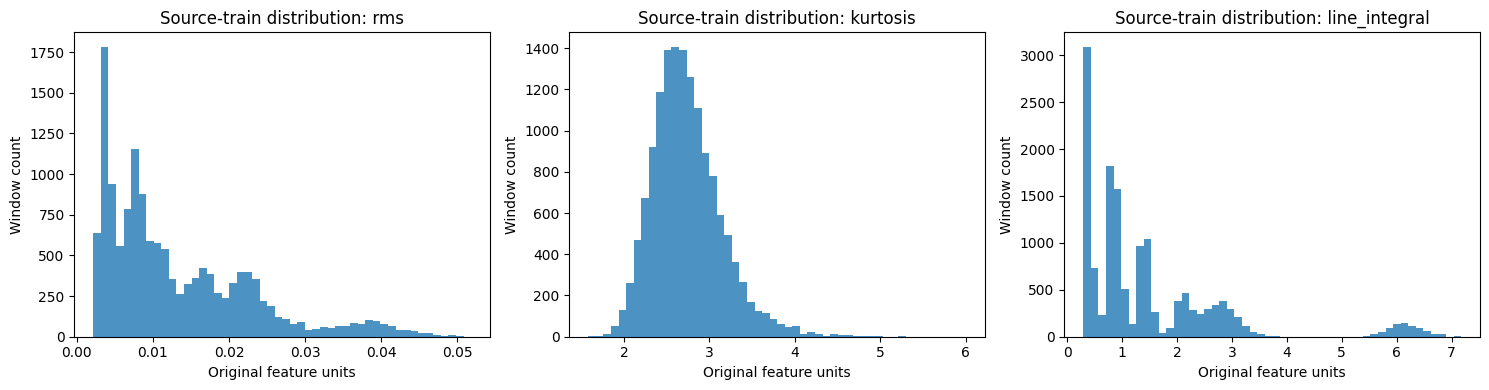

In [5]:
FEATURE_GROUPS = {
    "All 11": list(FEATURE_NAMES),
    "Amplitude only": ["rms", "var", "peak", "line_integral", "peak2peak"],
    "Shape only": ["crest", "kurtosis", "clearance", "shape", "skewness", "impulse"],
}
GROUP_INDICES = {
    name: np.array([FEATURE_NAMES.index(f) for f in names], dtype=int)
    for name, names in FEATURE_GROUPS.items()
}
assert set(FEATURE_GROUPS["Amplitude only"]).isdisjoint(
    FEATURE_GROUPS["Shape only"]
)
assert set(FEATURE_GROUPS["Amplitude only"] + FEATURE_GROUPS["Shape only"]) == set(FEATURE_NAMES)

mask = (DOMAINS != TARGET_DOMAIN[9]) & (SPLITS == 0)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axs, ["rms", "kurtosis", "line_integral"]):
    values = FEATURES[mask, FEATURE_NAMES.index(feature)]
    ax.hist(values, bins=50, alpha=0.8)
    ax.set_title(f"Source-train distribution: {feature}")
    ax.set_ylabel("Window count")
    ax.set_xlabel("Original feature units")
fig.tight_layout()
plt.show()

## 7. Define source-speed validation folds

For each task, the **real target speed is excluded entirely**. One of the remaining three source speeds becomes the simulated unseen validation speed.

Using `split == 1` on the held-out source domain and `split == 0` on the two training domains keeps the training/validation acquisition blocks separate.

In [6]:
def make_source_folds(task):
    target = TARGET_DOMAIN[task]
    sources = [d for d in range(4) if d != target]
    for held_domain in sources:
        train_domains = [d for d in sources if d != held_domain]
        train_mask = (SPLITS == 0) & np.isin(DOMAINS, train_domains)
        val_mask = (SPLITS == 1) & (DOMAINS == held_domain)

        train_idx = np.flatnonzero(train_mask)
        val_idx = np.flatnonzero(val_mask)

        assert len(train_idx) == 9600
        assert len(val_idx) == 1200
        assert not np.any(DOMAINS[train_idx] == target)
        assert not np.any(DOMAINS[val_idx] == target)
        assert np.intersect1d(train_idx, val_idx).size == 0

        yield held_domain, train_idx, val_idx

fold_overview = []
for task in TASKS:
    for held, train_idx, val_idx in make_source_folds(task):
        fold_overview.append({
            "task": task,
            "actual_target_hz_excluded": DOMAIN_HZ[TARGET_DOMAIN[task]],
            "train_hz": ", ".join(str(DOMAIN_HZ[x]) for x in
                                sorted(set(DOMAINS[train_idx]))),
            "held_source_hz": DOMAIN_HZ[held],
            "n_train": len(train_idx),
            "n_validation": len(val_idx),
        })

display(pd.DataFrame(fold_overview))

,task,actual_target_hz_excluded,train_hz,held_source_hz,n_train,n_validation
0,9,5,"20, 30",10,9600,1200
1,9,5,"10, 30",20,9600,1200
2,9,5,"10, 20",30,9600,1200
3,10,10,"20, 30",5,9600,1200
4,10,10,"5, 30",20,9600,1200
5,10,10,"5, 20",30,9600,1200
6,11,20,"10, 30",5,9600,1200
7,11,20,"5, 30",10,9600,1200
8,11,20,"5, 10",30,9600,1200
9,12,30,"10, 20",5,9600,1200


## 8. Smoke test — Task 9, first fold, all 11 features

Before running 108 fits, verify that the pipeline trains and measures cross-speed generalization on a **held-out source speed**.

The fold-specific scaler is fit on 9,600 training samples and only *transforms* the held-out speed's samples. Random Forest technically does not need scaling; using it consistently here makes the workflow compatible with a later neural-network feature branch.

In [7]:
held_domain, train_idx, val_idx = next(make_source_folds(9))
idx = GROUP_INDICES["All 11"]

scaler = StandardScaler()
x_train = scaler.fit_transform(FEATURES[train_idx][:, idx])
x_val = scaler.transform(FEATURES[val_idx][:, idx])
y_train = LABELS[train_idx]
y_val = LABELS[val_idx]

smoke_model = RandomForestClassifier(**RF_PARAMS, random_state=SEEDS[0])
smoke_model.fit(x_train, y_train)
smoke_predictions = smoke_model.predict(x_val)

print("Task 9 | held source speed:", DOMAIN_HZ[held_domain], "Hz")
print("Train accuracy:", round(100 * accuracy_score(y_train, smoke_model.predict(x_train)), 2), "%")
print("Cross-speed source-validation accuracy:",
      round(100 * accuracy_score(y_val, smoke_predictions), 2), "%")
print("Cross-speed macro-F1:",
      round(f1_score(y_val, smoke_predictions, average="macro", zero_division=0), 4))

Task 9 | held source speed: 10 Hz
Train accuracy: 99.11 %
Cross-speed source-validation accuracy: 18.25 %
Cross-speed macro-F1: 0.095


## 9. Full source-only validation — 4 tasks × 3 folds × 3 feature groups × 3 seeds

This is the core experiment. It saves *all* fold-level results as CSV.

- It uses no actual unseen target-domain rows.
- Scaling is fitted independently inside each fold.
- Every group uses the same split and same model hyperparameters.
- **Do not change model settings based on the actual target scores from the previous notebook.**

By default this trains 108 Random Forest models. Change `RUN_SOURCE_VALIDATION = False` after the results exist to load them instead of refitting.

In [8]:
RUNS_PATH = RESULTS_DIR / "source_domain_rf_folds.csv"

if RUN_SOURCE_VALIDATION:
    rows = []
    for task in TASKS:
        for held, train_idx, val_idx in make_source_folds(task):
            for group, idx in GROUP_INDICES.items():
                scaler = StandardScaler()
                x_train = scaler.fit_transform(FEATURES[train_idx][:, idx])
                x_val = scaler.transform(FEATURES[val_idx][:, idx])
                y_train, y_val = LABELS[train_idx], LABELS[val_idx]

                for seed in SEEDS:
                    model = RandomForestClassifier(**RF_PARAMS, random_state=seed)
                    model.fit(x_train, y_train)
                    preds = model.predict(x_val)
                    rows.append({
                        "task": task,
                        "actual_target_hz_excluded": DOMAIN_HZ[TARGET_DOMAIN[task]],
                        "held_source_domain": held,
                        "held_source_hz": DOMAIN_HZ[held],
                        "group": group,
                        "seed": seed,
                        "n_features": len(idx),
                        "train_n": len(train_idx),
                        "validation_n": len(val_idx),
                        "accuracy": accuracy_score(y_val, preds),
                        "macro_f1": f1_score(y_val, preds, average="macro", zero_division=0),
                    })
                print(f"Task {task} | source validation {DOMAIN_HZ[held]} Hz | {group}: complete")

    folds_df = pd.DataFrame(rows)
    folds_df.to_csv(RUNS_PATH, index=False)
    print("Saved:", RUNS_PATH)
else:
    if not RUNS_PATH.exists():
        raise FileNotFoundError(f"No saved results found: {RUNS_PATH}")
    folds_df = pd.read_csv(RUNS_PATH)

assert len(folds_df) == len(TASKS) * 3 * len(FEATURE_GROUPS) * len(SEEDS)
assert not folds_df.duplicated(["task", "held_source_domain", "group", "seed"]).any()
assert (folds_df["accuracy"].between(0, 1)).all()
assert (folds_df["macro_f1"].between(0, 1)).all()
assert (folds_df["held_source_hz"] != folds_df["actual_target_hz_excluded"]).all()
display(folds_df.head(12))

Task 9 | source validation 10 Hz | All 11: complete
Task 9 | source validation 10 Hz | Amplitude only: complete
Task 9 | source validation 10 Hz | Shape only: complete
Task 9 | source validation 20 Hz | All 11: complete
Task 9 | source validation 20 Hz | Amplitude only: complete
Task 9 | source validation 20 Hz | Shape only: complete
Task 9 | source validation 30 Hz | All 11: complete
Task 9 | source validation 30 Hz | Amplitude only: complete
Task 9 | source validation 30 Hz | Shape only: complete
Task 10 | source validation 5 Hz | All 11: complete
Task 10 | source validation 5 Hz | Amplitude only: complete
Task 10 | source validation 5 Hz | Shape only: complete
Task 10 | source validation 20 Hz | All 11: complete
Task 10 | source validation 20 Hz | Amplitude only: complete
Task 10 | source validation 20 Hz | Shape only: complete
Task 10 | source validation 30 Hz | All 11: complete
Task 10 | source validation 30 Hz | Amplitude only: complete
Task 10 | source validation 30 Hz | Shape o

,task,actual_target_hz_excluded,held_source_domain,held_source_hz,group,seed,n_features,train_n,validation_n,accuracy,macro_f1
0,9,5,1,10,All 11,0,11,9600,1200,0.182500,0.095039
1,9,5,1,10,All 11,1,11,9600,1200,0.175000,0.093585
2,9,5,1,10,All 11,2,11,9600,1200,0.180000,0.096630
3,9,5,1,10,Amplitude only,0,5,9600,1200,0.166667,0.055371
4,9,5,1,10,Amplitude only,1,5,9600,1200,0.166667,0.055325
5,9,5,1,10,Amplitude only,2,5,9600,1200,0.166667,0.055371
6,9,5,1,10,Shape only,0,6,9600,1200,0.198333,0.186400
7,9,5,1,10,Shape only,1,6,9600,1200,0.206667,0.195355
8,9,5,1,10,Shape only,2,6,9600,1200,0.209167,0.197904
9,9,5,2,20,All 11,0,11,9600,1200,0.002500,0.001775


## 10. Compare feature groups across source speeds

For each task and feature group, calculate mean **macro-F1** and accuracy. We average *first across seeds within each held-source-speed fold* and then across the three held-source folds, so every held-out speed has equal influence.

The variation across folds is informative: a group may transfer well to one speed but fail at another.

**Warning:** These metrics are not final unseen-target accuracies. They are intentionally source-only diagnostics.

,task,group,mean_accuracy,mean_macro_f1,sd_across_source_speeds,worst_source_macro_f1
2,9,Shape only,0.2500,0.2366,0.0521,0.1932
0,9,All 11,0.1157,0.0596,0.0511,0.0010
1,9,Amplitude only,0.1119,0.0447,0.0380,0.0025
5,10,Shape only,0.2119,0.2020,0.0226,0.1778
3,10,All 11,0.1697,0.0850,0.0332,0.0492
4,10,Amplitude only,0.1154,0.0414,0.0380,0.0003
8,11,Shape only,0.2037,0.1925,0.0173,0.1746
7,11,Amplitude only,0.1503,0.0694,0.0498,0.0341
6,11,All 11,0.1281,0.0583,0.0370,0.0278
11,12,Shape only,0.2093,0.2007,0.0279,0.1730


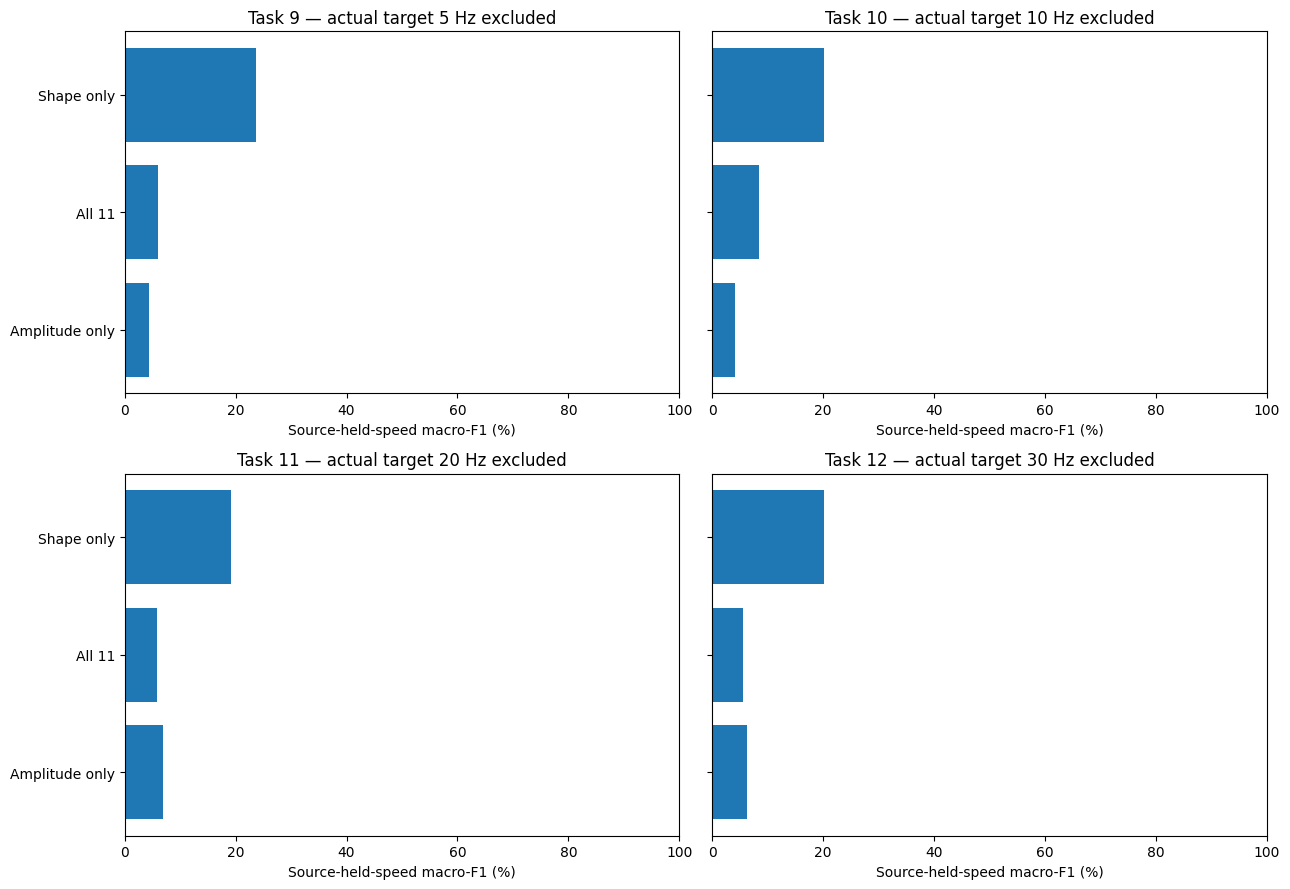

In [9]:
fold_means = (
    folds_df.groupby(["task", "held_source_hz", "group"], as_index=False)
    .agg(mean_accuracy=("accuracy", "mean"),
         mean_macro_f1=("macro_f1", "mean"),
         sd_across_rf_seeds=("macro_f1", "std"))
)

summary_df = (
    fold_means.groupby(["task", "group"], as_index=False)
    .agg(mean_accuracy=("mean_accuracy", "mean"),
         mean_macro_f1=("mean_macro_f1", "mean"),
         sd_across_source_speeds=("mean_macro_f1", "std"),
         worst_source_macro_f1=("mean_macro_f1", "min"))
)
display(summary_df.sort_values(["task", "mean_macro_f1"],
                               ascending=[True, False]).round(4))
summary_df.to_csv(RESULTS_DIR / "source_domain_group_summary.csv", index=False)

fig, axs = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, task in zip(axs.ravel(), TASKS):
    item = summary_df.loc[summary_df["task"] == task].sort_values("mean_macro_f1")
    ax.barh(item["group"], 100 * item["mean_macro_f1"])
    ax.set_title(f"Task {task} — actual target {DOMAIN_HZ[TARGET_DOMAIN[task]]} Hz excluded")
    ax.set_xlabel("Source-held-speed macro-F1 (%)")
    ax.set_xlim(0, 100)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "source_validation_group_macro_f1.png",
            dpi=180, bbox_inches="tight")
plt.show()

## 11. Select one feature group **per task** — source-only

The predeclared rule is:

1. Highest average macro-F1 across the three held-out *source* speeds.
2. If tied, higher mean source-held-speed accuracy.
3. If still tied, fewer features.

No target-domain metric enters this selection. A task-specific group may differ by target task because its available source speeds differ. Save the choice as a JSON **selection manifest** for later CNN fusion.

**Keep this manifest unchanged when evaluating subsequent architectures** unless you clearly label the new run as a different exploratory study.

In [10]:
summary_df["n_features"] = summary_df["group"].map(
    lambda group: len(FEATURE_GROUPS[group])
)
ranked = summary_df.sort_values(
    ["task", "mean_macro_f1", "mean_accuracy", "n_features", "group"],
    ascending=[True, False, False, True, True]
).copy()
# Rounded tolerance for exact ties: select using original full-precision metrics;
# fewer features only matters when earlier values are exactly equal.
selected_df = (
    ranked.groupby("task", as_index=False)
    .head(1)
    .sort_values("task")
    .reset_index(drop=True)
)

selection_manifest = {
    "study": "HUSTmotor acoustic source-domain feature selection",
    "unseen_target_data_used_for_selection": False,
    "dataset_file": DATA_PATH.name,
    "dataset_sha256": EXPECTED_SHA256,
    "source_validation": "leave one source speed out; fit split=0 on two speeds, score split=1 on third",
    "selection_metric": "mean source-held-speed macro_f1",
    "seeds": list(SEEDS),
    "rf_params": RF_PARAMS,
    "features": FEATURE_GROUPS,
    "choices": {
        str(int(row.task)): {
            "group": row.group,
            "feature_names": FEATURE_GROUPS[row.group],
            "mean_source_macro_f1": float(row.mean_macro_f1),
            "mean_source_accuracy": float(row.mean_accuracy)
        }
        for row in selected_df.itertuples()
    }
}
MANIFEST_PATH = RESULTS_DIR / "selected_feature_groups_source_only.json"
with open(MANIFEST_PATH, "w") as fh:
    json.dump(selection_manifest, fh, indent=2)

display(selected_df[["task", "group", "mean_macro_f1",
                     "mean_accuracy", "worst_source_macro_f1"]].round(4))
print("Saved selection manifest:", MANIFEST_PATH)

,task,group,mean_macro_f1,mean_accuracy,worst_source_macro_f1
0,9,Shape only,0.2366,0.2500,0.1932
1,10,Shape only,0.2020,0.2119,0.1778
2,11,Shape only,0.1925,0.2037,0.1746
3,12,Shape only,0.2007,0.2093,0.1730


Saved selection manifest: /content/drive/MyDrive/HUSTmotor_Source_Domain_Validation/results/selected_feature_groups_source_only.json


## 12. Inspect fold-level weaknesses

Plot macro-F1 at each held-out source speed for the selected group. **A high average with one very low fold is less reassuring** than consistently reasonable performance across all three speeds.

This is useful when planning CNN fusion: the goal is not simply to pick whichever group has the best training-domain classification, but to avoid speed-dependent shortcuts.

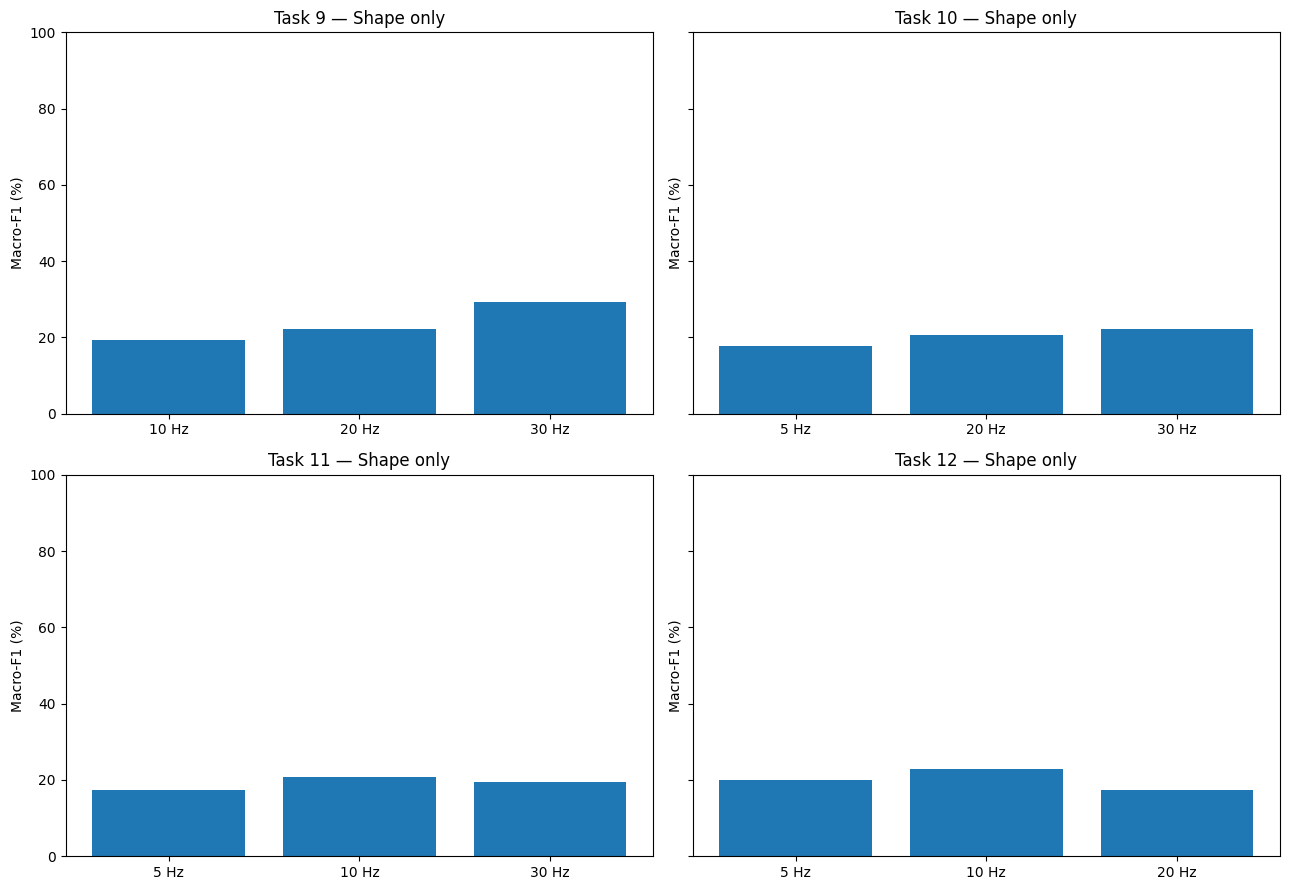

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, task in zip(axs.ravel(), TASKS):
    selected = selection_manifest["choices"][str(task)]["group"]
    part = (
        fold_means[(fold_means["task"] == task) &
                   (fold_means["group"] == selected)]
        .sort_values("held_source_hz")
    )
    ax.bar(part["held_source_hz"].astype(str) + " Hz",
           100 * part["mean_macro_f1"])
    ax.set_title(f"Task {task} — {selected}")
    ax.set_ylabel("Macro-F1 (%)")
    ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "selected_groups_per_source_speed.png",
            dpi=180, bbox_inches="tight")
plt.show()

## 13. Export a feature-selection record for the future CNN

This section writes all parameters and a short Markdown report. No trained Random Forest is needed as an input to the CNN. Later, we can take each task's **selected feature-name list**, standardize with the source-training split, and pass those numeric features into a separate small MLP branch.

The waveform branch should retain the existing z-score CNN preprocessing, given that it remains the strongest acoustic CNN baseline so far.

**Research limitation:** The actual target-domain results were viewed in previous exploratory notebooks. Therefore future target evaluations remain exploratory rather than an entirely untouched confirmatory test.

In [12]:
metadata = {
    "project": "UTC HUSTmotor acoustic source-domain validation",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "dataset_sha256": EXPECTED_SHA256,
    "tasks": list(TASKS),
    "seeds": list(SEEDS),
    "rf_params": RF_PARAMS,
    "notes": "Source-only fold selection; target rows excluded from all fitted models",
}
with open(RESULTS_DIR / "experiment_metadata.json", "w") as fh:
    json.dump(metadata, fh, indent=2)

lines = [
    "# HUSTmotor — Source-only feature selection",
    "",
    "All models were selected using held-out SOURCE speeds only.",
    "The actual target speeds were excluded from fitting and selection.",
    "",
    "| Task | Excluded target speed | Selected group | Mean source macro-F1 | Mean source accuracy |",
    "|---|---|---|---:|---:|"
]
for row in selected_df.itertuples():
    lines.append(
        f"| {int(row.task)} | {DOMAIN_HZ[TARGET_DOMAIN[int(row.task)]]} Hz "
        f"| {row.group} | {row.mean_macro_f1:.3f} | {row.mean_accuracy:.3f} |"
    )
lines += [
    "", "These are **source-domain validation** results, not unseen-target accuracy.",
    "The selection is exploratory because earlier experiments have already inspected target outcomes."
]
report_path = RESULTS_DIR / "source_selection_report.md"
report_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
print(report_path.read_text())
print("All artifacts saved under:", PROJECT_DIR)

# HUSTmotor — Source-only feature selection

All models were selected using held-out SOURCE speeds only.
The actual target speeds were excluded from fitting and selection.

| Task | Excluded target speed | Selected group | Mean source macro-F1 | Mean source accuracy |
|---|---|---|---:|---:|
| 9 | 5 Hz | Shape only | 0.237 | 0.250 |
| 10 | 10 Hz | Shape only | 0.202 | 0.212 |
| 11 | 20 Hz | Shape only | 0.193 | 0.204 |
| 12 | 30 Hz | Shape only | 0.201 | 0.209 |

These are **source-domain validation** results, not unseen-target accuracy.
The selection is exploratory because earlier experiments have already inspected target outcomes.

All artifacts saved under: /content/drive/MyDrive/HUSTmotor_Source_Domain_Validation


## 14. Next experiment: CNN + engineered acoustic feature branch

After running this notebook, send back **the executed `.ipynb`** and optionally `selected_feature_groups_source_only.json`. We can then implement:

1. Keep the original **1,024-point z-score acoustic waveform** input.
2. Feed selected acoustic features to an **MLP** (not a Random Forest).
3. Concatenate the CNN representation and the MLP representation.
4. Train the classifier using the same source-only model-selection protocol.
5. Compare against the original waveform-only CNN, reporting accuracy and macro-F1 by task.

**Do not choose the feature group by looking at target accuracy and retrying.** If several architectural candidates are explored, use only source-domain validation for architectural decisions, then report target performance with the appropriate exploratory caveat.

**References:** [HUSTmotor dataset](https://github.com/CHAOZHAO-1/HUSTmotor-multi-modal-dataset) · [Genti's preprocessing docs](https://github.com/Genti24-bit/ISCF_Project/blob/main/USAGE.md) · Zhao et al. (2025), *Engineering Applications of Artificial Intelligence*, 162, 112559.